# Compression d'image end-to-end (Ballé et al., ICLR 2017)
### Notebook de référence pour le challenge AIDGE IN SPACE (cas d'usage Viveris × CNES)

Ce notebook réimplémente en PyTorch le modèle de **J. Ballé, V. Laparra et E. Simoncelli, *End-to-end Optimized Image Compression*, ICLR 2017**, en s'inspirant du dépôt [liujiaheng/iclr_17_compression](https://github.com/liujiaheng/iclr_17_compression). Il sert de **référence logicielle** pour la suite du projet : tout ce qui sera porté plus tard avec Aidge puis LoCod (HLS) devra reproduire les sorties calculées ici.

**Ce que fait le notebook, dans l'ordre :**

1. construire les briques du modèle (GDN, transformée d'analyse, transformée de synthèse, modèle d'entropie) en expliquant chacune ;
2. entraîner le modèle sur le compromis débit/distorsion $L = \lambda \cdot D + R$ ;
3. l'évaluer sur le jeu Kodak (PSNR, bits par pixel) ;
4. **prouver la compression** avec un vrai codeur arithmétique : on écrit un fichier binaire, on le relit, on vérifie que le décodage est exact au bit près ;
5. comparer à JPEG et JPEG 2000 ;
6. **profiler** le modèle couche par couche (calcul, mémoire, opérations non linéaires) pour préparer la répartition CPU / FPGA ;
7. tester la sensibilité de l'encodeur à une quantification int8 des poids ;
8. exporter l'encodeur en ONNX (format d'entrée d'Aidge) avec des vecteurs de test « golden ».


## 0. Installation et configuration

Dépendances : `torch`, `numpy`, `pillow`, `matplotlib`, `pandas`, et pour la dernière section `onnx` (+ `onnxruntime` pour vérifier l'export). Pas forcément besoin de GPU : le notebook tourne sur CPU, simplement plus lentement.

In [1]:
import copy, io, json, math, os, platform, random, struct, time, urllib.request, bisect
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 1234
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device :", DEVICE)

PyTorch 2.7.1+cu118 | device : cuda


### Paramètres

Tous les réglages sont regroupés ici. Les plus importants :

- **`in_ch`** : 1 pour le niveau de gris (défaut), 3 pour le RGB.
- **`N`** : nombre de canaux internes et latents. L'article utilise 128 en niveaux de gris (192 ou 256 en RGB et aux hauts débits). C'est le paramètre qui pèse le plus sur le coût matériel : le calcul des convolutions 5×5 croît en $N^2$.
- **`lmbda`** : le poids de la distorsion dans la fonction de coût. Plus il est grand, plus le modèle privilégie la qualité au détriment du débit. Convention du dépôt de référence : distorsion = MSE sur des pixels dans $[0,1]$, avec $\lambda$ entre 256 (bas débit) et 8192 (haut débit).
- **`steps`** : nombre d'itérations. L'article entraîne pendant des millions d'itérations ; 50 000 itérations sur GPU donnent déjà un modèle correct pour valider la chaîne, mais pas les performances finales.
- **`MODE_RAPIDE`** : à mettre à `True` pour vérifier en quelques minutes que tout le notebook s'exécute de bout en bout (résultats non significatifs).

In [2]:
MODE_RAPIDE = True   # True : petit entraînement, juste pour vérifier que tout s'exécute
REENTRAINER = False   # False : si un checkpoint existe déjà pour cette config, on le recharge

CFG = {
    "in_ch": 1,            # 1 = niveaux de gris, 3 = RGB
    "N": 128,              # canaux internes / latents
    "gdn_last": True,      # GDN après la 3e convolution (article). False = variante du dépôt
    "lmbda": 2048,         # compromis débit / distorsion
    "crop": 256,           # taille des patchs d'entraînement (comme l'article)
    "batch_size": 16,
    "lr": 1e-4,            # Adam, comme l'article
    "steps": 50_000 if DEVICE.type == "cuda" else 5_000,
    "lr_decay_at": 0.8,    # on divise le pas par 10 à 80 % de l'entraînement
    "grad_clip": 5.0,      # écrêtage des gradients (dépôt de référence)
    "eval_every": 2_500,
    "n_patches": 8_000,    # patchs pré-extraits gardés sur le GPU (8000 x 256 x 256 en uint8 = 500 Mo)
    "num_workers": min(4, os.cpu_count() or 1) if platform.system() == "Linux" else 0,
}
if MODE_RAPIDE:
    CFG.update(steps=300, crop=128, batch_size=4, eval_every=150, n_patches=200)

N_EVAL_IMAGES = 2 if MODE_RAPIDE else 24   # images Kodak utilisées pour les évaluations finales

DATA_DIR  = Path("data")
KODAK_DIR = DATA_DIR / "kodak"     # jeu de test standard (24 images 768x512)
TRAIN_DIR = DATA_DIR / "train"     # images d'entraînement (png/jpg/tif, sous-dossiers acceptés)
OUT_DIR   = Path("outputs")
CKPT_DIR  = OUT_DIR / "checkpoints"
for d in (KODAK_DIR, TRAIN_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(json.dumps(CFG, indent=2))

{
  "in_ch": 1,
  "N": 128,
  "gdn_last": true,
  "lmbda": 2048,
  "crop": 128,
  "batch_size": 4,
  "lr": 0.0001,
  "steps": 300,
  "lr_decay_at": 0.8,
  "grad_clip": 5.0,
  "eval_every": 150,
  "n_patches": 200,
  "num_workers": 0
}


## 1. Données

**Test : Kodak.** Les 24 images Kodak (768×512) sont le jeu de test historique de la compression d'image ; l'article et quasiment toute la littérature y comparent leurs courbes débit/distorsion. Elles sont téléchargées automatiquement.

**Entraînement.** L'article utilise 6 507 images ImageNet. Trois options, par ordre de pertinence :

1. **des images lunaires ou planétaires en niveaux de gris** (archives publiques des missions LRO / LROC, Chang'e, etc.) : c'est ce qui rendra le modèle pertinent pour un rover, et c'est un argument fort devant un jury CNES ;
2. un jeu généraliste haute résolution comme [DIV2K](https://data.vision.ee.ethz.ch/cvl/DIV2K/) (800 images) ou CLIC ;
3. à défaut, si `data/train` est vide, le notebook s'entraîne sur Kodak lui-même. Cela suffit pour vérifier que la chaîne fonctionne, mais les scores sur Kodak seront alors **optimistes** (on teste sur les images d'entraînement).

**Prétraitement de l'article.** Ballé et al. sous-échantillonnent chaque image d'un facteur aléatoire inférieur à 0,75 avant d'en extraire un patch 256×256. Cela supprime le bruit et les artefacts JPEG des photos d'origine : sinon le réseau gaspillerait du débit à apprendre à reproduire des artefacts. On reproduit ce comportement, avec en plus des retournements aléatoires (augmentation de données).

In [3]:
def download_kodak(dest=KODAK_DIR):
    # Télécharge les 24 images Kodak (saute celles déjà présentes)
    base = "https://r0k.us/graphics/kodak/kodak/kodim{:02d}.png"
    for i in range(1, 25):
        f = dest / f"kodim{i:02d}.png"
        if f.exists():
            continue
        try:
            req = urllib.request.Request(base.format(i), headers={"User-Agent": "Mozilla/5.0"})
            f.write_bytes(urllib.request.urlopen(req, timeout=30).read())
        except Exception as e:
            print(f"Échec du téléchargement de {f.name} : {e}\n"
                  "Téléchargez les images à la main depuis https://r0k.us/graphics/kodak/ dans data/kodak")
            break
    found = sorted(dest.glob("*.png"))
    print(f"{len(found)} images Kodak disponibles dans {dest}")
    return found

def list_images(folder):
    exts = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
    return sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in exts)

kodak_paths = download_kodak()
train_paths = list_images(TRAIN_DIR)
if not train_paths:
    print("Aucune image dans data/train : entraînement sur Kodak (validation de la chaîne seulement).")
    train_paths = kodak_paths
print(f"{len(train_paths)} images d'entraînement")
assert kodak_paths, "Pas d'image de test : place les images Kodak dans data/kodak"

24 images Kodak disponibles dans data\kodak
Aucune image dans data/train : entraînement sur Kodak (validation de la chaîne seulement).
24 images d'entraînement


batch d'entraînement : (4, 1, 128, 128) | image Kodak : (1, 1, 512, 768)


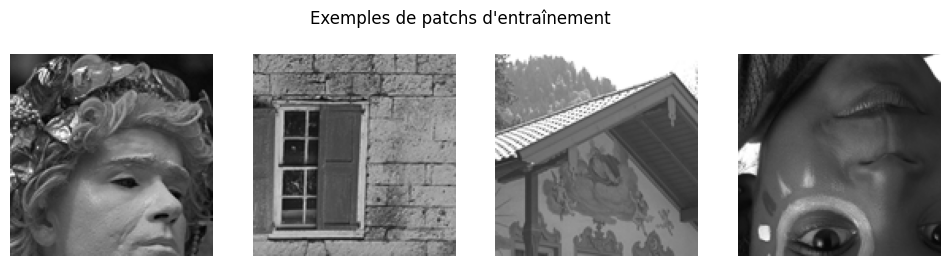

In [4]:
class CropDataset(Dataset):
    # Patchs aléatoires, avec le sous-échantillonnage aléatoire de l'article
    def __init__(self, paths, crop=256, in_ch=1, paper_downscale=True, repeats=50):
        self.paths, self.crop, self.in_ch = list(paths), crop, in_ch
        self.paper_downscale, self.repeats = paper_downscale, repeats

    def __len__(self):
        # chaque image fournit plusieurs patchs par "époque"
        return len(self.paths) * self.repeats

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx % len(self.paths)])
        img = img.convert("L" if self.in_ch == 1 else "RGB")
        c = self.crop
        w, h = img.size
        if self.paper_downscale:
            f_min = c / min(w, h)                 # facteur minimal pour qu'un patch tienne encore
            if f_min <= 0.75:
                f = random.uniform(max(f_min, 0.3), 0.75)
                img = img.resize((max(c, round(w * f)), max(c, round(h * f))), Image.BICUBIC)
        w, h = img.size
        if w < c or h < c:
            img = img.resize((max(w, c), max(h, c)), Image.BICUBIC)
            w, h = img.size
        x0, y0 = random.randint(0, w - c), random.randint(0, h - c)
        arr = np.asarray(img.crop((x0, y0, x0 + c, y0 + c)), dtype=np.float32) / 255.0
        arr = arr[None] if arr.ndim == 2 else arr.transpose(2, 0, 1)   # -> C x H x W
        if random.random() < 0.5: arr = arr[:, :, ::-1]
        if random.random() < 0.5: arr = arr[:, ::-1, :]
        return torch.from_numpy(arr.copy())

def load_image(path, in_ch=1):
    # Image complète -> tenseur 1 x C x H x W dans [0, 1]
    img = Image.open(path).convert("L" if in_ch == 1 else "RGB")
    arr = np.asarray(img, dtype=np.float32) / 255.0
    arr = arr[None] if arr.ndim == 2 else arr.transpose(2, 0, 1)
    return torch.from_numpy(arr.copy())[None]

train_set = CropDataset(train_paths, CFG["crop"], CFG["in_ch"])
train_loader = DataLoader(train_set, batch_size=CFG["batch_size"], shuffle=True,
                          num_workers=CFG["num_workers"], drop_last=True)
kodak_imgs = [load_image(p, CFG["in_ch"]) for p in kodak_paths]

batch = next(iter(train_loader))
print("batch d'entraînement :", tuple(batch.shape), "| image Kodak :", tuple(kodak_imgs[0].shape))
fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for i in range(4):
    ax[i].imshow(batch[i].permute(1, 2, 0).squeeze(), cmap="gray", vmin=0, vmax=1); ax[i].axis("off")
plt.suptitle("Exemples de patchs d'entraînement"); plt.show()

## 2. Le modèle, brique par brique

Rappel du schéma général (figure 1 de l'article) :

$$x \xrightarrow{\;g_a\;} y \xrightarrow{\;\text{arrondi}\;} q \xrightarrow{\;\text{codage entropique}\;} \text{bits} \xrightarrow{\;\text{décodage}\;} \hat y = q \xrightarrow{\;g_s\;} \hat x$$

- $g_a$ (**analyse**) transforme l'image en une représentation latente $y$ plus petite et plus « compressible ». **C'est la partie qui tourne sur le rover.**
- L'arrondi produit des entiers $q$ : c'est la seule perte d'information du système.
- Le **codage entropique** transforme $q$ en bits sans perte, en utilisant un modèle de probabilité $p(q)$ appris. Aussi sur le rover.
- $g_s$ (**synthèse**) reconstruit l'image. Elle tourne côté réception (plateforme ou sol), à confirmer avec Viveris.

### 2.1 La GDN (Generalized Divisive Normalization)

C'est la non-linéarité propre à ce modèle, à la place des ReLU habituelles. Pour chaque position spatiale $(m,n)$ et chaque canal $i$ :

$$u_i = \frac{w_i}{\sqrt{\beta_i + \sum_j \gamma_{ij}\, w_j^2}}$$

Chaque canal est divisé par une « énergie locale » qui mélange tous les canaux au même endroit. Cette normalisation, inspirée des neurones du cortex visuel, rend les coefficients beaucoup plus indépendants statistiquement (proches d'une gaussienne), ce qui est exactement ce dont le codeur entropique a besoin puisqu'il code chaque coefficient séparément.

**Lecture matérielle, importante pour le FPGA :** la somme $\sum_j \gamma_{ij} w_j^2$ est une **convolution 1×1** appliquée à $w^2$. Une GDN = un carré élément par élément, une convolution 1×1 de $N$ vers $N$ canaux, une racine carrée et une division. On pourra donc réutiliser l'accélérateur de convolution, et remplacer racine + division par une table de $1/\sqrt{\cdot}$ suivie d'une multiplication.

**La synthèse utilise l'IGDN**, une inverse approchée : $\hat w_i = \hat u_i \cdot \sqrt{\hat\beta_i + \sum_j \hat\gamma_{ij}\, \hat u_j^2}$ (multiplication au lieu de division), avec ses propres paramètres.

**Pourquoi la reparamétrisation ?** Il faut $\beta > 0$ et $\gamma \ge 0$, sinon la racine peut porter sur un nombre négatif ou la division sur zéro. On n'optimise donc pas $\beta$ directement mais $\beta'$ avec $\beta = \beta'^2 - \epsilon$, borné inférieurement. Le carré adoucit les gradients près de zéro, là où l'optimisation devient instable. L'opérateur `LowerBound` fait un `max(x, borne)` mais laisse passer le gradient s'il pousse la valeur vers le haut, pour qu'un paramètre collé à la borne puisse s'en décoller.

**Symétrie :** l'article force $\gamma_{ij} = \gamma_{ji}$. On stocke une matrice pleine et on utilise $(\gamma + \gamma^\top)/2$, ce qui donne $N(N+1)/2 + N = 8\,384$ paramètres libres pour $N=128$, exactement le chiffre de la figure 8.

In [5]:
class LowerBound(torch.autograd.Function):
    # max(x, borne) dont le gradient passe quand x >= borne OU quand il pousse x vers le haut
    @staticmethod
    def forward(ctx, x, bound):
        ctx.save_for_backward(x)
        ctx.bound = bound
        return x.clamp(min=bound)

    @staticmethod
    def backward(ctx, grad):
        (x,) = ctx.saved_tensors
        pass_through = (x >= ctx.bound) | (grad < 0)
        return grad * pass_through.to(grad.dtype), None

def lower_bound(x, bound):
    if torch.is_grad_enabled() and x.requires_grad:
        return LowerBound.apply(x, bound)
    return x.clamp(min=bound)      # en inférence : simple clamp (exportable en ONNX)


class GDN(nn.Module):
    def __init__(self, ch, inverse=False, beta_min=1e-6, gamma_init=0.1,
                 reparam_offset=2 ** -18, symmetric=True):
        super().__init__()
        self.ch, self.inverse, self.symmetric = ch, inverse, symmetric
        self.pedestal = reparam_offset ** 2
        self.beta_bound = (beta_min + self.pedestal) ** 0.5
        self.gamma_bound = reparam_offset
        # initialisation : beta = 1, gamma = 0.1 * identité (chaque canal normalisé surtout par lui-même)
        self.beta = nn.Parameter(torch.sqrt(torch.ones(ch) + self.pedestal))
        self.gamma = nn.Parameter(torch.sqrt(gamma_init * torch.eye(ch) + self.pedestal))

    def effective_params(self):
        beta = lower_bound(self.beta, self.beta_bound) ** 2 - self.pedestal
        gamma = lower_bound(self.gamma, self.gamma_bound) ** 2 - self.pedestal
        if self.symmetric:
            gamma = 0.5 * (gamma + gamma.t())
        return beta, gamma

    def forward(self, x):
        beta, gamma = self.effective_params()
        norm = F.conv2d(x * x, gamma.view(self.ch, self.ch, 1, 1), beta)   # conv 1x1 sur x^2
        norm = torch.sqrt(norm)
        return x * norm if self.inverse else x / norm

    def extra_repr(self):
        return f"ch={self.ch}, inverse={self.inverse}, symmetric={self.symmetric}"


g = GDN(128)
free = 128 * 129 // 2 + 128 if g.symmetric else 128 * 128 + 128
print(f"GDN(128) : {sum(p.numel() for p in g.parameters())} valeurs stockées, {free} paramètres libres (article : 8384)")
t = torch.randn(2, 128, 8, 8)
print("forme conservée :", tuple(g(t).shape))

GDN(128) : 16512 valeurs stockées, 8384 paramètres libres (article : 8384)
forme conservée : (2, 128, 8, 8)


### 2.2 Transformée d'analyse $g_a$ (l'encodeur embarqué)

Trois étages « convolution, sous-échantillonnage, GDN » (figure 8 de l'article) :

| Étage | Convolution | Pas (stride) | Sortie pour une entrée 256×256×1 |
|---|---|---|---|
| 1 | 9×9, 1 → 128 canaux | 4 | 64×64×128 |
| 2 | 5×5, 128 → 128 | 2 | 32×32×128 |
| 3 | 5×5, 128 → 128 | 2 | 16×16×128 |

Réduction spatiale totale : 16 dans chaque direction. Le latent contient $128 \times 16 \times 16 = 32\,768$ valeurs pour $65\,536$ pixels, soit la moitié de la dimension d'entrée (comme dit l'article) : **la compression ne vient donc pas de la réduction de dimension**, mais du fait que la plupart des valeurs arrondies valent 0 ou ±1 et se codent en très peu de bits.

**Point d'implémentation :** le sous-échantillonnage est fait par le *stride* de la convolution. On ne calcule que les sorties conservées ; calculer la convolution complète puis jeter 15 valeurs sur 16 serait 16 fois plus coûteux au premier étage. À garder en tête pour le HLS.

Le *padding* (4 pour le noyau 9×9, 2 pour les 5×5) garantit des dimensions exactement divisées par 4 puis 2 : les images doivent avoir des côtés multiples de 16 (on complètera par réplication des bords sinon).

### 2.3 Transformée de synthèse $g_s$

Symétrique de l'analyse, ordre inversé dans chaque étage : IGDN, sur-échantillonnage, convolution. Sur-échantillonnage et convolution sont fusionnés dans une **convolution transposée** (`ConvTranspose2d`), comme dans le dépôt de référence. Le paramètre `output_padding` corrige les tailles pour retrouver exactement l'image d'origine.

In [6]:
class AnalysisTransform(nn.Module):
    def __init__(self, in_ch=1, N=128, gdn_last=True):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, N, 9, stride=4, padding=4)
        self.gdn1 = GDN(N)
        self.conv2 = nn.Conv2d(N, N, 5, stride=2, padding=2)
        self.gdn2 = GDN(N)
        self.conv3 = nn.Conv2d(N, N, 5, stride=2, padding=2)
        self.gdn3 = GDN(N) if gdn_last else nn.Identity()
        for c in (self.conv1, self.conv2, self.conv3):        # init du dépôt de référence
            nn.init.xavier_normal_(c.weight, math.sqrt(2)); nn.init.constant_(c.bias, 0.01)

    def forward(self, x):
        x = self.gdn1(self.conv1(x))
        x = self.gdn2(self.conv2(x))
        return self.gdn3(self.conv3(x))


class SynthesisTransform(nn.Module):
    def __init__(self, in_ch=1, N=128, gdn_last=True):
        super().__init__()
        self.igdn1 = GDN(N, inverse=True) if gdn_last else nn.Identity()
        self.deconv1 = nn.ConvTranspose2d(N, N, 5, stride=2, padding=2, output_padding=1)
        self.igdn2 = GDN(N, inverse=True)
        self.deconv2 = nn.ConvTranspose2d(N, N, 5, stride=2, padding=2, output_padding=1)
        self.igdn3 = GDN(N, inverse=True)
        self.deconv3 = nn.ConvTranspose2d(N, in_ch, 9, stride=4, padding=4, output_padding=3)
        for c in (self.deconv1, self.deconv2, self.deconv3):
            nn.init.xavier_normal_(c.weight, math.sqrt(2)); nn.init.constant_(c.bias, 0.01)

    def forward(self, y):
        y = self.deconv1(self.igdn1(y))
        y = self.deconv2(self.igdn2(y))
        return self.deconv3(self.igdn3(y))


ga = AnalysisTransform(CFG["in_ch"], CFG["N"], CFG["gdn_last"])
gs = SynthesisTransform(CFG["in_ch"], CFG["N"], CFG["gdn_last"])
x = torch.rand(1, CFG["in_ch"], 256, 256)
y = ga(x)
print("image :", tuple(x.shape), "-> latent :", tuple(y.shape), "-> reconstruction :", tuple(gs(y).shape))
print(f"rapport de dimension latent / image : {y.numel() / x.numel():.2f}")

image : (1, 1, 256, 256) -> latent : (1, 128, 16, 16) -> reconstruction : (1, 1, 256, 256)
rapport de dimension latent / image : 0.50


### 2.4 Le modèle d'entropie : combien de bits coûte chaque latent ?

Le codeur entropique a besoin d'une probabilité $P(q_i = k)$ pour chaque valeur possible. Le coût d'un symbole est $-\log_2 P$ bits (théorie de Shannon) : une valeur probable coûte peu, une valeur rare coûte cher. Le débit total est donc

$$R = \sum_i -\log_2 P(q_i).$$

**Hypothèse factorisée :** on suppose les latents indépendants, avec une même loi pour toutes les positions d'un canal donné (128 lois, une par canal). C'est précisément ce que la GDN cherche à rendre vrai.

**Comment représenter cette loi ?** L'article 2017 utilise une densité linéaire par morceaux (une spline). Comme le dépôt de référence, on utilise la version de l'article de 2018 (*Variational image compression with a scale hyperprior*, annexe 6.1) : on apprend directement la **fonction de répartition** $c(x)$ sous la forme d'un petit réseau monotone croissant, terminé par une sigmoïde pour rester entre 0 et 1. Chaque couche fait $x \mapsto x \cdot \text{softplus}(h) + b$ (pente positive, donc croissante), puis $x \mapsto x + \tanh(x)\tanh(a)$, croissante car sa dérivée $1 + \tanh(a)(1-\tanh^2 x)$ reste positive.

La probabilité qu'un latent arrondi vaille $k$ est la masse de l'intervalle $[k-\tfrac12, k+\tfrac12]$ :

$$P(q = k) = c(k + \tfrac12) - c(k - \tfrac12).$$

**Détail numérique :** dans les queues de la distribution, les deux sigmoïdes valent presque 1 et leur différence est noyée dans les erreurs d'arrondi flottant. On utilise l'identité $\sigma(a) - \sigma(b) = \sigma(-b) - \sigma(-a)$ pour toujours calculer la différence du côté où les valeurs sont petites (astuce de TensorFlow Compression et CompressAI). Le dépôt de référence ne le fait pas.

**Pour le matériel :** ce réseau ne sert qu'à l'entraînement. Une fois le modèle figé, on le remplace par des **tables de fréquences entières** (section 5), qui seront stockées en mémoire morte sur le rover.

In [7]:
class FactorizedEntropyModel(nn.Module):
    def __init__(self, ch, n_layers=4):
        super().__init__()
        init = lambda: nn.Parameter(torch.randn(1, ch, 1, 1) * 0.01)
        self.h = nn.ParameterList([init() for _ in range(n_layers)])
        self.b = nn.ParameterList([init() for _ in range(n_layers)])
        self.a = nn.ParameterList([init() for _ in range(n_layers - 1)])

    def logits_cdf(self, x):
        # Fonction de répartition AVANT la sigmoïde finale (croissante en x)
        for k in range(len(self.h)):
            x = x * F.softplus(self.h[k]) + self.b[k]
            if k < len(self.a):
                x = x + torch.tanh(x) * torch.tanh(self.a[k])
        return x

    def likelihood(self, y, min_p=1e-9):
        lower = self.logits_cdf(y - 0.5)
        upper = self.logits_cdf(y + 0.5)
        s = -torch.sign(lower + upper).detach()          # côté où la différence est précise
        s = torch.where(s == 0, torch.ones_like(s), s)
        p = torch.abs(torch.sigmoid(s * upper) - torch.sigmoid(s * lower))
        return p.clamp(min=min_p) if min_p > 0 else p

    def forward(self, y):
        return self.likelihood(y)

em = FactorizedEntropyModel(CFG["N"])
p = em(torch.zeros(1, CFG["N"], 1, 1))
print("P(q=0) à l'initialisation (canal 0) :", round(p[0, 0, 0, 0].item(), 4))

P(q=0) à l'initialisation (canal 0) : 0.0567


### 2.5 Assemblage et fonction de coût

**Le problème de l'arrondi.** L'arrondi a une dérivée nulle presque partout : impossible d'entraîner par descente de gradient à travers lui. L'idée centrale de l'article : **pendant l'entraînement, on remplace l'arrondi par l'ajout d'un bruit uniforme** $\mathcal U(-\tfrac12, \tfrac12)$. L'erreur ressemble à celle de l'arrondi (même amplitude, même variance $1/12$), mais tout reste dérivable. La figure 4 de l'article montre que les débits et distorsions ainsi estimés collent à ceux obtenus avec le vrai arrondi. **En inférence, on arrondit vraiment.**

**La fonction de coût** est le compromis débit/distorsion de Lagrange :

$$L = \lambda \cdot \underbrace{\text{MSE}(x, \hat x)}_{D} + \underbrace{\frac{1}{H W}\sum_i -\log_2 P(\tilde y_i)}_{R \text{ en bits par pixel}}$$

Chaque valeur de $\lambda$ produit **un modèle** correspondant à **un point** de la courbe débit/distorsion. Pour tracer une courbe, il faut entraîner plusieurs modèles (dans l'article, l'information $\lambda$ est même écrite dans le flux binaire pour que le décodeur choisisse les bons paramètres).

**Indicateurs :**
- **bpp** (bits par pixel) : débit. Une image 8 bits non compressée en niveaux de gris fait 8 bpp ; à 0,5 bpp le taux de compression est donc de 16.
- **PSNR** $= 10\log_{10}(1/\text{MSE})$ en dB, pour des pixels dans $[0,1]$ : qualité. Au-delà de 35 à 40 dB, les différences deviennent difficiles à voir.

In [8]:
class E2ECompressor(nn.Module):
    def __init__(self, in_ch=1, N=128, gdn_last=True):
        super().__init__()
        self.in_ch, self.N = in_ch, N
        self.g_a = AnalysisTransform(in_ch, N, gdn_last)
        self.g_s = SynthesisTransform(in_ch, N, gdn_last)
        self.entropy_model = FactorizedEntropyModel(N)

    def forward(self, x):
        y = self.g_a(x)
        if self.training:
            y_hat = y + torch.empty_like(y).uniform_(-0.5, 0.5)   # proxy dérivable de l'arrondi
        else:
            y_hat = torch.round(y)                               # vraie quantification
        x_hat = self.g_s(y_hat)
        return {"y": y, "y_hat": y_hat, "x_hat": x_hat, "likelihoods": self.entropy_model(y_hat)}


def total_bits(likelihoods):
    return (-torch.log2(likelihoods)).sum()

def rd_loss(out, x, lmbda):
    n_pix = x.shape[0] * x.shape[2] * x.shape[3]
    bpp = total_bits(out["likelihoods"]) / n_pix
    mse = F.mse_loss(out["x_hat"], x)
    return lmbda * mse + bpp, mse, bpp

def psnr(a, b):
    mse = F.mse_loss(a, b).item()
    return 100.0 if mse == 0 else 10 * math.log10(1.0 / mse)

def pad_to_multiple(x, m=16):
    H, W = x.shape[-2:]
    Hp, Wp = math.ceil(H / m) * m, math.ceil(W / m) * m
    return F.pad(x, (0, Wp - W, 0, Hp - H), mode="replicate"), (H, W)


def count(m):
    return sum(p.numel() for p in m.parameters())

model = E2ECompressor(CFG["in_ch"], CFG["N"], CFG["gdn_last"]).to(DEVICE)
print(f"Paramètres  g_a : {count(model.g_a):>9,} | g_s : {count(model.g_s):>9,} | entropie : {count(model.entropy_model):,}")
for name, m in model.g_a.named_children():
    if isinstance(m, nn.Conv2d):
        print(f"  {name}: poids {m.weight.numel():>7,} (article fig. 8, niveaux de gris : {'10 368' if name == 'conv1' else '409 600'})")

Paramètres  g_a :   879,488 | g_s :   879,361 | entropie : 1,408
  conv1: poids  10,368 (article fig. 8, niveaux de gris : 10 368)
  conv2: poids 409,600 (article fig. 8, niveaux de gris : 409 600)
  conv3: poids 409,600 (article fig. 8, niveaux de gris : 409 600)


## 3. Entraînement

Boucle classique, avec les choix de l'article et du dépôt :

- **Adam**, pas initial $10^{-4}$, divisé par 10 en fin d'entraînement (l'article le divise chaque fois que débit et distorsion stagnent, jusqu'à $10^{-7}$) ;
- **écrêtage des gradients** à ±5 (dépôt de référence) : la GDN et le modèle d'entropie peuvent produire des gradients ponctuellement très forts ;
- évaluation périodique sur quelques images Kodak avec le **vrai arrondi**, pour suivre l'écart entre entraînement (bruit) et inférence (arrondi).

**Pour occuper le GPU :** le modèle est petit, donc un GPU attend vite les données. Plutôt que d'ouvrir et redimensionner une grande image à chaque patch (travail CPU qui affame le GPU), on **pré-extrait une fois pour toutes** quelques milliers de patchs, stockés en uint8 directement sur le GPU ; chaque batch est ensuite tiré au hasard et retourné sur le GPU, sans aucun chargement. Deux autres détails comptent : les métriques sont cumulées sur le GPU et lues seulement tous les 200 pas (chaque `.item()` force le CPU à attendre la fin du calcul GPU), et `cudnn.benchmark` laisse cuDNN choisir l'algorithme de convolution le plus rapide. Augmentez `n_patches` pour un vrai entraînement sur un gros jeu de données (diversité des patchs).

Le modèle et son historique sont sauvegardés dans `outputs/checkpoints/`, un fichier par $\lambda$, **tous les 5 000 pas** : une interruption ne fait rien perdre. Si le fichier existe déjà et que `REENTRAINER = False`, on le recharge au lieu de réentraîner.

**Ordres de grandeur :** sur un GPU récent, comptez quelques minutes pour 10 000 itérations. Sur CPU, l'entraînement est lent : utilisez de préférence une machine équipée d'un GPU (poste personnel, serveur de calcul ou Google Colab), puis revenez au CPU pour les sections suivantes si besoin.

In [ ]:
@torch.no_grad()
def evaluate(model, images):
    # PSNR (sur l'image ré-arrondie en 8 bits) et débit estimé par le modèle d'entropie
    model.eval()
    psnrs, bpps = [], []
    for x in images:
        xp, (H, W) = pad_to_multiple(x)
        out = model(xp.to(DEVICE))
        x_hat = out["x_hat"][..., :H, :W].clamp(0, 1).cpu()
        x_hat = torch.round(x_hat * 255) / 255
        psnrs.append(psnr(x, x_hat))
        bpps.append(total_bits(out["likelihoods"]).item() / (H * W))
    return float(np.mean(psnrs)), float(np.mean(bpps))


def ckpt_path(cfg):
    return CKPT_DIR / f"bls2017_c{cfg['in_ch']}_N{cfg['N']}_lambda{cfg['lmbda']}.pt"


# Réglages GPU sans risque pour la précision de l'entraînement
torch.backends.cudnn.benchmark = True          # cuDNN choisit l'algo de conv le plus rapide (tailles fixes)
torch.backends.cuda.matmul.allow_tf32 = True   # TF32 sur les GPU Ampere et plus récents
torch.backends.cudnn.allow_tf32 = True

def build_patch_bank(paths, n_patches=4000, crop=256, in_ch=1, device=DEVICE):
    # Extrait une fois pour toutes des patchs (avec le sous-échantillonnage de l'article) et les garde en uint8
    per_img = max(1, math.ceil(n_patches / len(paths)))
    patches, t0 = [], time.time()
    for p in paths:
        img = Image.open(p).convert("L" if in_ch == 1 else "RGB")
        w, h = img.size
        f_min = crop / min(w, h)
        if f_min <= 0.75:                       # un facteur aléatoire par image, puis plusieurs crops
            f = random.uniform(max(f_min, 0.3), 0.75)
            img = img.resize((max(crop, round(w * f)), max(crop, round(h * f))), Image.BICUBIC)
        elif f_min > 1:
            img = img.resize((max(w, crop), max(h, crop)), Image.BICUBIC)
        arr = np.asarray(img)
        arr = arr[None] if arr.ndim == 2 else arr.transpose(2, 0, 1)
        H, W = arr.shape[1:]
        for _ in range(per_img):
            y0, x0 = random.randint(0, H - crop), random.randint(0, W - crop)
            patches.append(arr[:, y0:y0 + crop, x0:x0 + crop].copy())
    bank = torch.from_numpy(np.stack(patches)).to(device)
    print(f"{len(bank)} patchs {tuple(bank.shape[1:])} en {time.time()-t0:.0f} s, "
          f"{bank.numel()/2**20:.0f} Mo sur {bank.device}")
    return bank

def sample_batch(bank, batch_size):
    # Tirage aléatoire + retournements, entièrement sur le GPU
    idx = torch.randint(len(bank), (batch_size,), device=bank.device)
    x = bank[idx].to(DEVICE).float().div_(255)
    if random.random() < 0.5: x = x.flip(-1)
    if random.random() < 0.5: x = x.flip(-2)
    return x

def train(model, bank, cfg, eval_images, path, log_every=200, save_every=5000):
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    hist = defaultdict(list)
    decay_step = int(cfg["lr_decay_at"] * cfg["steps"])
    run = torch.zeros(3, device=DEVICE)      # loss, mse, bpp cumulés SUR le GPU : pas de synchro à chaque pas
    n, t0, t_log = 0, time.time(), time.time()
    for step in range(1, cfg["steps"] + 1):
        model.train()
        if step == decay_step:
            for gr in opt.param_groups:
                gr["lr"] *= 0.1
        x = sample_batch(bank, cfg["batch_size"])
        out = model(x)
        loss, mse, bpp = rd_loss(out, x, cfg["lmbda"])
        opt.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_value_(model.parameters(), cfg["grad_clip"])
        opt.step()
        run += torch.stack([loss.detach(), mse.detach(), bpp.detach()]); n += 1

        last = step == cfg["steps"]
        if step % log_every == 0 or last:
            l, m, b = (run / n).tolist(); run.zero_(); n = 0      # une seule synchro tous les log_every pas
            hist["step"].append(step); hist["loss"].append(l); hist["bpp"].append(b)
            hist["psnr"].append(10 * math.log10(1 / max(m, 1e-10)))
            it_s = log_every / (time.time() - t_log); t_log = time.time()
            eta = (cfg["steps"] - step) / max(it_s, 1e-9) / 60
            print(f"step {step:>7}/{cfg['steps']} | {it_s:5.1f} it/s | reste ~{eta:4.1f} min | "
                  f"loss {l:.4f} | {b:.3f} bpp | {hist['psnr'][-1]:.2f} dB")
        if step % cfg["eval_every"] == 0 or last:
            p_ev, b_ev = evaluate(model, eval_images)
            hist["eval_step"].append(step); hist["eval_psnr"].append(p_ev); hist["eval_bpp"].append(b_ev)
            print(f"   -> Kodak (arrondi) : {b_ev:.3f} bpp, {p_ev:.2f} dB")
        if step % save_every == 0 or last:                    # sauvegarde régulière : rien n'est perdu si on interrompt
            torch.save({"state_dict": model.state_dict(), "cfg": cfg, "history": dict(hist), "step": step}, path)
    print(f"Terminé en {(time.time()-t0)/60:.1f} min, modèle sauvegardé : {path}")
    return dict(hist)



eval_subset = kodak_imgs[: (2 if MODE_RAPIDE else 4)]
path = ckpt_path(CFG)
if path.exists() and not REENTRAINER:
    ck = torch.load(path, map_location=DEVICE)
    model.load_state_dict(ck["state_dict"]); history = ck["history"]
    print(f"Checkpoint rechargé : {path}")
else:
    bank = build_patch_bank(train_paths, CFG["n_patches"], CFG["crop"], CFG["in_ch"])
    history = train(model, bank, CFG, eval_subset, path)

NameError: name 'history' is not defined

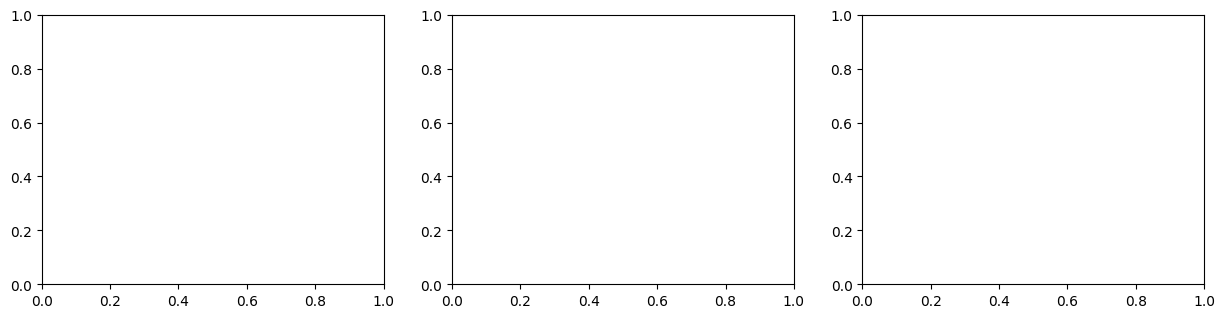

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].plot(history["step"], history["loss"]); ax[0].set_title("Coût L = λ·MSE + bpp"); ax[0].set_yscale("log")
ax[1].plot(history["step"], history["bpp"], label="entraînement (bruit)")
ax[1].plot(history["eval_step"], history["eval_bpp"], "o-", label="Kodak (arrondi)"); ax[1].set_title("Débit (bpp)")
ax[2].plot(history["step"], history["psnr"], label="entraînement (bruit)")
ax[2].plot(history["eval_step"], history["eval_psnr"], "o-", label="Kodak (arrondi)"); ax[2].set_title("PSNR (dB)")
for a in ax: a.set_xlabel("itération"); a.grid(alpha=0.3)
ax[1].legend(); ax[2].legend(); plt.tight_layout(); plt.show()

**Comment lire ces courbes.** Au début, le débit monte (le réseau apprend à transmettre de l'information) puis redescend pendant que la qualité continue de progresser : le modèle apprend à mieux répartir les bits. Les points Kodak (arrondi réel) doivent rester proches des courbes d'entraînement (bruit) ; un grand écart signalerait que l'approximation par bruit uniforme fonctionne mal.

## 4. Résultats visuels et anatomie du latent

On compresse une image Kodak et on regarde ce que le réseau a appris. Deux observations sont utiles pour la suite :

- **les bits par canal** : en général, une partie des canaux ne transmet presque rien (le latent vaut 0 partout). C'est une piste d'optimisation matérielle directe : supprimer ces canaux (*pruning*) réduit le calcul de la dernière convolution sans perte notable ;
- **l'histogramme d'un canal** comparé à la loi apprise par le modèle d'entropie : s'ils coïncident, le codeur arithmétique atteindra un débit proche de l'estimation.

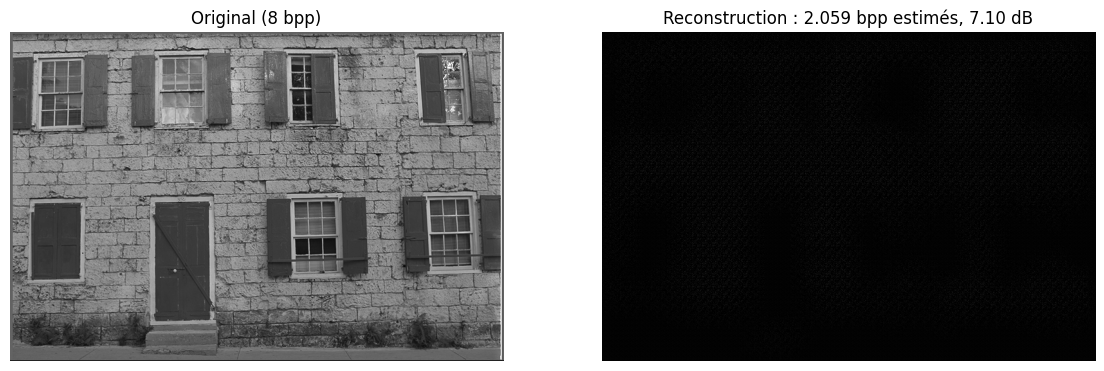

Latent : (128, 32, 48), valeurs entre -1 et 1, 98.7 % de zéros
116 canaux sur 128 portent 90 % des bits


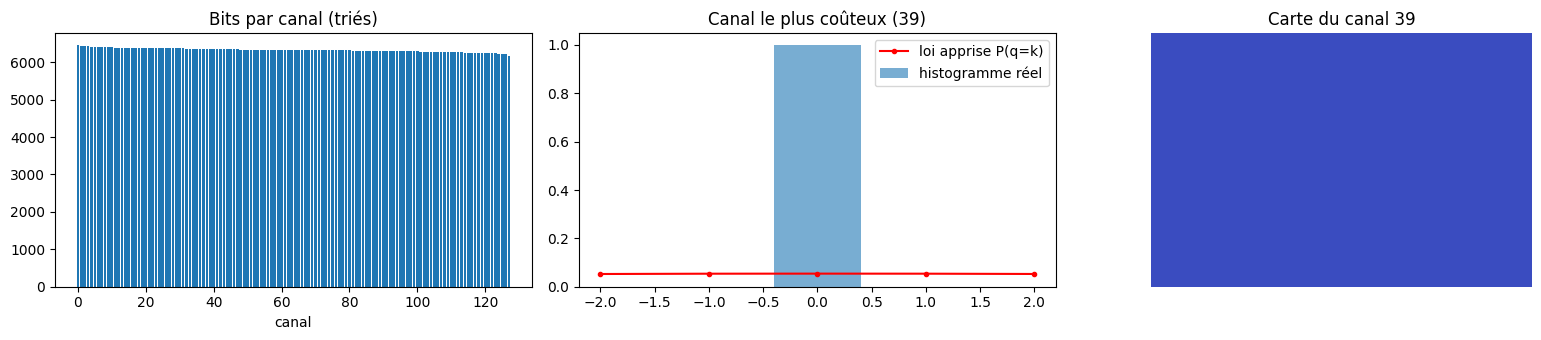

: 

In [ ]:
model.eval()
x = kodak_imgs[0]
with torch.no_grad():
    xp, (H, W) = pad_to_multiple(x)
    out = model(xp.to(DEVICE))
x_hat = torch.round(out["x_hat"][..., :H, :W].clamp(0, 1).cpu() * 255) / 255
q = out["y_hat"][0].cpu()
bits_map = -torch.log2(out["likelihoods"][0]).cpu()
bpp_est = bits_map.sum().item() / (H * W)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
cm = "gray" if CFG["in_ch"] == 1 else None
ax[0].imshow(x[0].permute(1, 2, 0).squeeze(), cmap=cm, vmin=0, vmax=1); ax[0].set_title("Original (8 bpp)")
ax[1].imshow(x_hat[0].permute(1, 2, 0).squeeze(), cmap=cm, vmin=0, vmax=1)
ax[1].set_title(f"Reconstruction : {bpp_est:.3f} bpp estimés, {psnr(x, x_hat):.2f} dB")
for a in ax: a.axis("off")
plt.show()

bits_per_channel = bits_map.sum(dim=(1, 2)).numpy()
order = np.argsort(bits_per_channel)[::-1]
share = np.cumsum(bits_per_channel[order]) / bits_per_channel.sum()
n90 = int(np.searchsorted(share, 0.9)) + 1
print(f"Latent : {tuple(q.shape)}, valeurs entre {int(q.min())} et {int(q.max())}, "
      f"{(q == 0).float().mean().item()*100:.1f} % de zéros")
print(f"{n90} canaux sur {CFG['N']} portent 90 % des bits")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
ax[0].bar(range(CFG["N"]), bits_per_channel[order]); ax[0].set_title("Bits par canal (triés)"); ax[0].set_xlabel("canal")
c0 = int(order[0])
vals, counts = np.unique(q[c0].numpy().astype(int), return_counts=True)
k = torch.arange(vals.min() - 2, vals.max() + 3, dtype=torch.float32)
with torch.no_grad():
    grid = torch.zeros(1, CFG["N"], 1, len(k)); grid[0, c0, 0] = k
    pmf = model.entropy_model.likelihood(grid.to(DEVICE), min_p=0)[0, c0, 0].cpu()
ax[1].bar(vals, counts / counts.sum(), alpha=0.6, label="histogramme réel")
ax[1].plot(k, pmf, "r.-", label="loi apprise P(q=k)")
ax[1].set_title(f"Canal le plus coûteux ({c0})"); ax[1].legend()
ax[2].imshow(q[c0], cmap="coolwarm"); ax[2].set_title(f"Carte du canal {c0}"); ax[2].axis("off")
plt.tight_layout(); plt.show()

## 5. Preuve de compression : un vrai codeur arithmétique

Jusqu'ici, le débit était **estimé** par $\sum -\log_2 P$. Pour un livrable, il faut un **vrai fichier** qui se décode. Le dépôt de référence s'arrête à l'estimation ; on va plus loin.

### 5.1 Principe du codage arithmétique

On représente tout le message par un seul nombre dans $[0, 1)$. On part de l'intervalle $[0, 1)$ ; pour chaque symbole, on le découpe en sous-intervalles proportionnels aux probabilités des symboles possibles, et on garde celui du symbole réellement émis. Un symbole de probabilité $p$ réduit la largeur de l'intervalle d'un facteur $p$, donc coûte $-\log_2 p$ bits : on atteint presque exactement le débit estimé.

En pratique, on travaille avec des **entiers 32 bits** : dès que le bit de poids fort des deux bornes est identique, il est définitif, on l'écrit et on décale (renormalisation). Le cas délicat où l'intervalle se resserre autour de 1/2 sans que le bit de tête soit décidé est géré par un compteur de bits « en attente ». L'implémentation suit le schéma classique de Witten, Neal et Cleary (1987), facile à transposer en C. L'article utilise CABAC (le codeur binaire de H.264), plus complexe ; le principe est identique.

### 5.2 Des probabilités aux tables de fréquences entières

Le codeur travaille sur des **fréquences entières** dont la somme vaut $2^{16}$ :

1. pour chaque canal, on évalue $P(q=k)$ sur une plage de valeurs et on garde le support $[k_{min}, k_{max}]$ hors duquel la probabilité est négligeable ;
2. on ajoute un **symbole d'échappement** qui récupère la masse des queues : une valeur hors support est codée par l'échappement suivi de sa valeur brute en binaire. Le système reste ainsi sans perte quoi qu'il arrive, sans réserver de place à des valeurs qui n'arrivent jamais ;
3. on convertit en entiers, chaque symbole recevant **au moins 1** (une probabilité nulle rendrait le symbole impossible à coder).

Ces tables sont **figées** après l'entraînement et identiques à l'encodage et au décodage : sur le rover, ce sont quelques dizaines de kilo-octets en mémoire morte, et le réseau du modèle d'entropie disparaît complètement.

### 5.3 Pourquoi cette partie restera sur le CPU

Le codage arithmétique est **intrinsèquement séquentiel** (chaque symbole modifie l'état utilisé par le suivant) et plein de branchements. Il se parallélise mal sur FPGA, alors qu'un cœur ARM le fait très bien. Ordre des symboles : canal par canal, puis balayage ligne par ligne, comme dans l'article.

In [ ]:
@torch.no_grad()
def build_cdf_tables(model, precision=16, tail_mass=1e-9, max_range=255):
    em = model.entropy_model.eval()
    C = model.N
    k = torch.arange(-max_range, max_range + 1, dtype=torch.float32)
    grid = k.view(1, 1, 1, -1).expand(1, C, 1, -1).contiguous().to(next(em.parameters()).device)
    pmf = em.likelihood(grid, min_p=0)[0, :, 0, :].double().cpu().numpy()     # C x K
    total = 1 << precision
    lo, cums = [], []
    for c in range(C):
        p = pmf[c]
        left, right = np.cumsum(p), np.cumsum(p[::-1])[::-1]
        i0 = int(np.argmax(left > tail_mass))
        i1 = len(p) - 1 - int(np.argmax(right[::-1] > tail_mass))
        if i0 == 0 or i1 == len(p) - 1:
            print(f"attention : support du canal {c} tronqué, augmenter max_range")
        support = p[i0:i1 + 1]
        escape = max(1.0 - support.sum(), 1e-12)
        probs = np.append(support, escape)
        L = len(probs)
        freq = np.floor(probs / probs.sum() * (total - L)).astype(np.int64) + 1   # au moins 1
        freq[np.argmax(freq)] += total - freq.sum()                              # somme exacte
        lo.append(int(k[i0])); cums.append([0] + np.cumsum(freq).tolist())
    return {"lo": lo, "cum": cums, "total": total, "precision": precision}

tables = build_cdf_tables(model)
sizes = [len(c) - 1 for c in tables["cum"]]
print(f"Tables : {len(sizes)} canaux, {min(sizes)} à {max(sizes)} symboles par canal (échappement compris)")
print(f"Taille en ROM (fréquences cumulées sur 16 bits + bornes) : {sum(len(c) for c in tables['cum'])*2/1024:.1f} Ko")

In [ ]:
class BitWriter:
    def __init__(self):
        self.buf, self.cur, self.n = bytearray(), 0, 0
    def write(self, bit):
        self.cur = (self.cur << 1) | bit; self.n += 1
        if self.n == 8:
            self.buf.append(self.cur); self.cur, self.n = 0, 0
    def getvalue(self):
        if self.n:
            return bytes(self.buf) + bytes([self.cur << (8 - self.n)])
        return bytes(self.buf)

class BitReader:
    def __init__(self, data):
        self.data, self.pos = data, 0
    def read(self):
        byte = self.pos >> 3
        if byte >= len(self.data):
            return 0                          # au-delà de la fin : des zéros
        bit = (self.data[byte] >> (7 - (self.pos & 7))) & 1
        self.pos += 1
        return bit

STATE_BITS = 32
FULL, HALF, QUARTER = 1 << STATE_BITS, 1 << (STATE_BITS - 1), 1 << (STATE_BITS - 2)
MASK = FULL - 1

class ArithmeticEncoder:
    def __init__(self):
        self.low, self.high, self.pending, self.out = 0, MASK, 0, BitWriter()

    def encode(self, cum_lo, cum_hi, total):
        rng = self.high - self.low + 1
        self.high = self.low + (rng * cum_hi) // total - 1
        self.low = self.low + (rng * cum_lo) // total
        while ((self.low ^ self.high) & HALF) == 0:          # bit de tête décidé : on l'écrit
            bit = self.low >> (STATE_BITS - 1)
            self.out.write(bit)
            for _ in range(self.pending):
                self.out.write(bit ^ 1)
            self.pending = 0
            self.low = (self.low << 1) & MASK
            self.high = ((self.high << 1) & MASK) | 1
        while (self.low & ~self.high & QUARTER) != 0:        # intervalle coincé autour de 1/2
            self.pending += 1
            self.low = (self.low << 1) ^ HALF
            self.high = ((self.high ^ HALF) << 1) | HALF | 1

    def finish(self):
        self.out.write(1)
        return self.out.getvalue()

class ArithmeticDecoder:
    def __init__(self, data):
        self.inp = BitReader(data)
        self.low, self.high, self.code = 0, MASK, 0
        for _ in range(STATE_BITS):
            self.code = (self.code << 1) | self.inp.read()

    def decode(self, cum, total):
        rng = self.high - self.low + 1
        value = ((self.code - self.low + 1) * total - 1) // rng
        s = bisect.bisect_right(cum, value) - 1               # symbole tel que cum[s] <= value < cum[s+1]
        self.high = self.low + (rng * cum[s + 1]) // total - 1
        self.low = self.low + (rng * cum[s]) // total
        while ((self.low ^ self.high) & HALF) == 0:
            self.code = ((self.code << 1) & MASK) | self.inp.read()
            self.low = (self.low << 1) & MASK
            self.high = ((self.high << 1) & MASK) | 1
        while (self.low & ~self.high & QUARTER) != 0:
            self.code = (self.code & HALF) | ((self.code << 1) & (MASK >> 1)) | self.inp.read()
            self.low = (self.low << 1) ^ HALF
            self.high = ((self.high ^ HALF) << 1) | HALF | 1
        return s


# Test unitaire : séquence aléatoire suivant une loi connue, codage puis décodage
rng_np = np.random.default_rng(0)
freqs = [3000, 20000, 30000, 10000, 2536]
cum = [0] + np.cumsum(freqs).tolist()
msg = rng_np.choice(5, size=20000, p=np.array(freqs) / sum(freqs))
enc = ArithmeticEncoder()
for s in msg:
    enc.encode(cum[s], cum[s + 1], cum[-1])
data = enc.finish()
dec = ArithmeticDecoder(data)
back = [dec.decode(cum, cum[-1]) for _ in range(len(msg))]
p = np.array(freqs) / sum(freqs)
print("Décodage exact :", list(back) == list(msg))
print(f"{len(data)*8/len(msg):.4f} bits/symbole, entropie théorique {-(p*np.log2(p)).sum():.4f}")

### 5.4 Format du fichier et chaîne complète

Le flux binaire commence par un en-tête de 14 octets (signature, version, taille d'origine de l'image, nombre de canaux couleur, $\lambda$, $N$), comme les informations de bord décrites dans l'annexe 6.2 de l'article, suivi des symboles codés arithmétiquement.

- `compress` : padding à un multiple de 16, $g_a$, arrondi, codage arithmétique. **C'est exactement la chaîne embarquée.**
- `decompress` : lecture de l'en-tête, décodage arithmétique, $g_s$, recadrage.

In [ ]:
MAGIC, VERSION = b"E2E1", 1
HEADER = ">4sBHHBHH"            # signature, version, H, W, in_ch, lambda, N
BYPASS_BITS = 20                # valeur brute après un échappement (zigzag)

def encode_symbols(q, tables):
    # q : tableau int C x h x w -> octets
    enc = ArithmeticEncoder(); total = tables["total"]; n_esc = 0
    for c in range(q.shape[0]):
        lo, cum = tables["lo"][c], tables["cum"][c]
        esc = len(cum) - 2
        for v in q[c].ravel().tolist():
            s = v - lo
            if 0 <= s < esc:
                enc.encode(cum[s], cum[s + 1], total)
            else:
                enc.encode(cum[esc], cum[esc + 1], total); n_esc += 1
                z = 2 * v if v >= 0 else -2 * v - 1
                assert z < (1 << BYPASS_BITS)
                for b in range(BYPASS_BITS - 1, -1, -1):
                    bit = (z >> b) & 1
                    enc.encode(bit, bit + 1, 2)
    return enc.finish(), n_esc

def decode_symbols(data, shape, tables):
    dec = ArithmeticDecoder(data); total = tables["total"]
    C, h, w = shape
    q = np.empty(shape, dtype=np.int32)
    for c in range(C):
        lo, cum = tables["lo"][c], tables["cum"][c]
        esc = len(cum) - 2
        flat = q[c].reshape(-1)
        for i in range(h * w):
            s = dec.decode(cum, total)
            if s < esc:
                flat[i] = s + lo
            else:
                z = 0
                for _ in range(BYPASS_BITS):
                    z = (z << 1) | dec.decode([0, 1, 2], 2)
                flat[i] = z // 2 if z % 2 == 0 else -(z + 1) // 2
    return q

@torch.no_grad()
def compress(model, tables, x, lmbda):
    model.eval()
    xp, (H, W) = pad_to_multiple(x)
    y = model.g_a(xp.to(DEVICE))
    q = torch.round(y)[0].cpu().numpy().astype(np.int32)
    payload, n_esc = encode_symbols(q, tables)
    header = struct.pack(HEADER, MAGIC, VERSION, H, W, model.in_ch, int(lmbda), model.N)
    return header + payload, q, n_esc

@torch.no_grad()
def decompress(model, tables, stream):
    model.eval()
    hs = struct.calcsize(HEADER)
    magic, ver, H, W, in_ch, lmbda, N = struct.unpack(HEADER, stream[:hs])
    assert magic == MAGIC and N == model.N and in_ch == model.in_ch
    shape = (N, math.ceil(H / 16), math.ceil(W / 16))
    q = decode_symbols(stream[hs:], shape, tables)
    x_hat = model.g_s(torch.from_numpy(q).float()[None].to(DEVICE))
    x_hat = x_hat[..., :H, :W].clamp(0, 1).cpu()
    return torch.round(x_hat * 255) / 255, q


x = kodak_imgs[0]
t0 = time.time(); stream, q_enc, n_esc = compress(model, tables, x, CFG["lmbda"]); t_enc = time.time() - t0
bin_path = OUT_DIR / "kodim01.e2e"; bin_path.write_bytes(stream)
t0 = time.time(); x_dec, q_dec = decompress(model, tables, bin_path.read_bytes()); t_dec = time.time() - t0

H, W = x.shape[-2:]
with torch.no_grad():
    lik = model.entropy_model(torch.from_numpy(q_enc).float()[None].to(DEVICE))
bpp_est = total_bits(lik).item() / (H * W)
bpp_real = len(stream) * 8 / (H * W)
raw_bytes = H * W * CFG["in_ch"]
print(f"Latents identiques après décodage : {np.array_equal(q_enc, q_dec)}  (échappements : {n_esc})")
print(f"Fichier : {len(stream):,} octets, contre {raw_bytes:,} en brut 8 bits -> taux de compression {raw_bytes/len(stream):.1f}")
print(f"Débit réel {bpp_real:.4f} bpp | estimé {bpp_est:.4f} bpp | écart {100*(bpp_real/bpp_est-1):+.2f} %")
print(f"PSNR après décodage du fichier : {psnr(x, x_dec):.2f} dB")
print(f"Temps (Python pur, indicatif) : encodage {t_enc:.2f} s, décodage {t_dec:.2f} s")

L'**écart** entre débit réel et estimé vient de l'en-tête, de l'arrondi des probabilités en fréquences entières sur 16 bits et de la terminaison du codeur. Il doit rester de l'ordre du pourcent, parfois même légèrement négatif (l'arrondi des fréquences peut, par hasard, mieux coller aux statistiques réelles de l'image). C'est la preuve que le débit estimé pendant l'entraînement est atteignable en pratique.

Les temps affichés sont ceux d'un codeur en **Python pur**, très lent : une version C fera le même travail des dizaines de fois plus vite. Ce qui compte ici, c'est que le coût est **proportionnel au nombre de latents** ($N \cdot H \cdot W / 256$) et qu'il est séquentiel.

## 6. Comparaison avec JPEG et JPEG 2000

Pour chaque modèle entraîné (un fichier par $\lambda$ dans `outputs/checkpoints/`), on mesure le **débit réel** (fichier produit par le codeur arithmétique) et le PSNR sur les images Kodak. On compare à JPEG et JPEG 2000 (via Pillow) sur les mêmes images.

Pour obtenir une vraie courbe, relancez l'entraînement avec d'autres valeurs de `CFG["lmbda"]` (par exemple 512, 1024, 4096, 8192) : chaque checkpoint ajoutera un point. Pour le jury CNES, la comparaison la plus parlante serait aussi le standard spatial **CCSDS 122.0** (compression par ondelettes utilisée à bord) ; il n'existe pas dans Pillow, mais des implémentations libres existent et JPEG 2000, proche dans son principe, sert d'approximation ici.

L'article montre que ce modèle bat JPEG à tous les débits et JPEG 2000 en PSNR à la plupart des débits, avec un gain visuel net aux bas débits (pas d'effet de blocs ni de ringing). Avec un entraînement court, attendez-vous à être plus proche de JPEG 2000 que dans l'article.

In [ ]:
rd_imgs = kodak_imgs[:N_EVAL_IMAGES]

def to_pil(x):
    a = (x[0].permute(1, 2, 0).squeeze(-1).numpy() * 255).round().astype(np.uint8)
    return Image.fromarray(a)

def from_pil(img, in_ch):
    a = np.asarray(img.convert("L" if in_ch == 1 else "RGB"), dtype=np.float32) / 255
    a = a[None] if a.ndim == 2 else a.transpose(2, 0, 1)
    return torch.from_numpy(a.copy())[None]

def codec_rd(imgs, fmt, settings):
    pts = []
    for s in settings:
        bpps, psnrs = [], []
        for x in imgs:
            buf = io.BytesIO()
            if fmt == "JPEG":
                to_pil(x).save(buf, "JPEG", quality=s)
            else:
                to_pil(x).save(buf, "JPEG2000", quality_mode="rates", quality_layers=[s])
            H, W = x.shape[-2:]
            bpps.append(buf.tell() * 8 / (H * W))
            psnrs.append(psnr(x, from_pil(Image.open(io.BytesIO(buf.getvalue())), CFG["in_ch"])))
        pts.append((np.mean(bpps), np.mean(psnrs)))
    return np.array(sorted(pts))

jpeg_pts = codec_rd(rd_imgs, "JPEG", [5, 10, 20, 30, 50, 70, 85, 95])
try:
    j2k_pts = codec_rd(rd_imgs, "JPEG2000", [80, 50, 30, 20, 12, 8, 5, 3])
except Exception as e:
    j2k_pts = None; print("JPEG 2000 indisponible dans cette installation de Pillow :", e)

ours = []
pattern = f"bls2017_c{CFG['in_ch']}_N*_lambda*.pt"
for f in sorted(CKPT_DIR.glob(pattern)):
    ck = torch.load(f, map_location=DEVICE)
    m = E2ECompressor(ck["cfg"]["in_ch"], ck["cfg"]["N"], ck["cfg"]["gdn_last"]).to(DEVICE)
    m.load_state_dict(ck["state_dict"]); m.eval()
    tb = build_cdf_tables(m)
    bpps, psnrs = [], []
    for x in rd_imgs:
        st, _, _ = compress(m, tb, x, ck["cfg"]["lmbda"])
        xd, _ = decompress(m, tb, st)
        H, W = x.shape[-2:]
        bpps.append(len(st) * 8 / (H * W)); psnrs.append(psnr(x, xd))
    ours.append((ck["cfg"]["lmbda"], np.mean(bpps), np.mean(psnrs)))
    print(f"λ = {ck['cfg']['lmbda']:>5} : {np.mean(bpps):.3f} bpp (réel), {np.mean(psnrs):.2f} dB")

plt.figure(figsize=(7, 5))
plt.plot(jpeg_pts[:, 0], jpeg_pts[:, 1], "s-", label="JPEG")
if j2k_pts is not None:
    plt.plot(j2k_pts[:, 0], j2k_pts[:, 1], "^-", label="JPEG 2000")
if ours:
    o = np.array(sorted([(b, p) for _, b, p in ours]))
    plt.plot(o[:, 0], o[:, 1], "o-", color="crimson", lw=2, ms=8, label="Ballé 2017 (ce notebook, débit réel)")
plt.xlabel("débit (bits par pixel)"); plt.ylabel("PSNR (dB)"); plt.xlim(0, 2.0)
plt.title(f"Courbe débit/distorsion, {len(rd_imgs)} image(s) Kodak")
plt.grid(alpha=0.3); plt.legend(); plt.show()

In [ ]:
# Comparaison visuelle à débit équivalent : on cherche la qualité JPEG la plus proche du débit de notre modèle
x = kodak_imgs[0]; H, W = x.shape[-2:]
st, _, _ = compress(model, tables, x, CFG["lmbda"]); x_ours, _ = decompress(model, tables, st)
bpp_ours = len(st) * 8 / (H * W)
best = None
for qual in range(1, 96):
    buf = io.BytesIO(); to_pil(x).save(buf, "JPEG", quality=qual)
    b = buf.tell() * 8 / (H * W)
    if best is None or abs(b - bpp_ours) < abs(best[1] - bpp_ours):
        best = (qual, b, buf.getvalue())
x_jpeg = from_pil(Image.open(io.BytesIO(best[2])), CFG["in_ch"])

ys, xs = slice(H // 4, H // 4 + 192), slice(W // 3, W // 3 + 256)   # zoom
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, img, title in zip(ax, [x, x_jpeg, x_ours],
                         ["Original",
                          f"JPEG q={best[0]} : {best[1]:.3f} bpp, {psnr(x, x_jpeg):.2f} dB",
                          f"Ballé 2017 : {bpp_ours:.3f} bpp, {psnr(x, x_ours):.2f} dB"]):
    a.imshow(img[0].permute(1, 2, 0).squeeze()[ys, xs], cmap="gray" if CFG["in_ch"] == 1 else None, vmin=0, vmax=1)
    a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()

## 7. Profilage pour la partition CPU / FPGA

C'est la section qui prépare directement la répartition des calculs entre CPU et FPGA. Deux approches complémentaires :

**1. Profilage analytique (indépendant du matériel).** Pour chaque couche, on compte :
- les **MAC** (multiplications-accumulations), unité de base du calcul d'un réseau de neurones et de la charge d'un accélérateur FPGA ;
- les opérations **non linéaires coûteuses** (racines carrées, divisions) : en HLS, une division ou une racine flottante coûte bien plus cher qu'une MAC en ressources et en latence ;
- la **mémoire** : taille des poids et des activations (sorties de couche), en float32 et en int8.

Ces chiffres sont exacts, quel que soit le processeur. Ce sont eux qui doivent guider la partition.

**2. Profilage mesuré (sur cette machine).** On chronomètre chaque couche avec un seul thread pour se rapprocher d'un cœur embarqué. **Attention :** sur un PC, PyTorch utilise des noyaux très optimisés (vectorisation AVX, cache), et le classement des couches peut différer de celui de la cible. Le chronométrage qui fera foi sera celui de l'export C d'Aidge exécuté sur l'ARM de la carte : le scheduler d'Aidge sait produire le temps de chaque opérateur.

On profile pour une image **512×512**, taille plausible pour une caméra de navigation de rover (à ajuster quand Viveris aura précisé le capteur).

In [ ]:
def profile_layers(module, input_shape, bytes_per_act=4):
    rows, hooks = [], []
    def hook(m, inp, out):
        x = inp[0]; o = out
        name = layer_names[m]
        if isinstance(m, nn.Conv2d):
            kind = f"Conv {m.kernel_size[0]}x{m.kernel_size[1]} s{m.stride[0]}"
            macs = o[0].numel() * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
            nl = 0
        elif isinstance(m, nn.ConvTranspose2d):
            kind = f"ConvT {m.kernel_size[0]}x{m.kernel_size[1]} s{m.stride[0]}"
            macs = x[0].numel() * (m.out_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
            nl = 0
        else:   # GDN / IGDN (ou version gelée)
            inv = getattr(m, "inverse", False)
            kind = "IGDN" if inv else "GDN"
            C, h, w = o.shape[1:]
            macs = h * w * C * C + h * w * C          # conv 1x1 sur x^2 + calcul des carrés
            nl = 2 * h * w * C                        # une racine + une division (ou mult.) par valeur
        rows.append({
            "couche": name, "type": kind,
            "entrée": "x".join(map(str, x.shape[1:])), "sortie": "x".join(map(str, o.shape[1:])),
            "paramètres": sum(p.numel() for p in m.parameters()),
            "MAC (M)": macs / 1e6, "sqrt+div (M)": nl / 1e6,
            "activation sortie fp32 (Mo)": o[0].numel() * 4 / 2**20,
            "activation sortie int8 (Mo)": o[0].numel() / 2**20,
        })
    layer_names = {}
    for name, m in module.named_modules():
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, GDN)) or type(m).__name__ == "FrozenGDN":
            layer_names[m] = name
            hooks.append(m.register_forward_hook(hook))
    with torch.no_grad():
        module.eval()(torch.zeros(input_shape, device=next(module.parameters()).device))
    for h in hooks: h.remove()
    df = pd.DataFrame(rows)
    df["% MAC"] = 100 * df["MAC (M)"] / df["MAC (M)"].sum()
    return df

PROFILE_SHAPE = (1, CFG["in_ch"], 512, 512)
df_enc = profile_layers(model.g_a, PROFILE_SHAPE)
df_dec = profile_layers(model.g_s, (1, CFG["N"], 512 // 16, 512 // 16))
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("ENCODEUR (embarqué sur le rover), image", "x".join(map(str, PROFILE_SHAPE[1:])))
display(df_enc)
print(f"Total encodeur : {df_enc['MAC (M)'].sum()/1e3:.2f} GMAC, "
      f"{df_enc['sqrt+div (M)'].sum():.1f} M racines/divisions, "
      f"{df_enc['paramètres'].sum():,} paramètres "
      f"({df_enc['paramètres'].sum()*4/2**20:.2f} Mo fp32, {df_enc['paramètres'].sum()/2**20:.2f} Mo int8)")
print(f"Total décodeur : {df_dec['MAC (M)'].sum()/1e3:.2f} GMAC")

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
colors = ["tab:blue" if t.startswith("Conv") else "tab:orange" for t in df_enc["type"]]
ax[0].bar(df_enc["couche"], df_enc["% MAC"], color=colors)
ax[0].set_title("Encodeur : part du calcul (bleu = conv, orange = GDN)"); ax[0].set_ylabel("% des MAC")
ax[1].bar(df_enc["couche"], df_enc["activation sortie fp32 (Mo)"], color=colors, label="fp32")
ax[1].bar(df_enc["couche"], df_enc["activation sortie int8 (Mo)"], color="k", alpha=0.4, label="int8")
ax[1].set_title("Encodeur : taille de la sortie de chaque couche"); ax[1].set_ylabel("Mo"); ax[1].legend()
plt.tight_layout(); plt.show()

# Pic mémoire d'une exécution naïve couche par couche : entrée + sortie de la couche la plus gourmande
in_bytes = [np.prod(PROFILE_SHAPE[1:]) * 4] + list(df_enc["activation sortie fp32 (Mo)"] * 2**20)[:-1]
peak = max(i + o * 2**20 for i, o in zip(in_bytes, df_enc["activation sortie fp32 (Mo)"]))
print(f"Pic mémoire naïf (entrée + sortie d'une couche, fp32) : {peak/2**20:.1f} Mo, "
      f"soit environ {peak/4/2**20:.1f} Mo en int8. À comparer à la BRAM du FPGA cible (souvent < 1 Mo sur un Zynq-7000).")

In [ ]:
@torch.no_grad()
def time_layers(module, input_shape, repeats=5, threads=1):
    old = torch.get_num_threads(); torch.set_num_threads(threads)
    module = module.eval().cpu()
    times, t_start, hooks = defaultdict(list), {}, []
    for name, m in module.named_modules():
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, GDN)):
            hooks.append(m.register_forward_pre_hook(lambda m, i, n=name: t_start.__setitem__(n, time.perf_counter())))
            hooks.append(m.register_forward_hook(lambda m, i, o, n=name: times[n].append(time.perf_counter() - t_start[n])))
    x = torch.rand(input_shape)
    module(x)                                   # échauffement
    times.clear()
    for _ in range(repeats):
        module(x)
    for h in hooks: h.remove()
    torch.set_num_threads(old); module.to(DEVICE)
    return pd.Series({k: np.median(v) * 1e3 for k, v in times.items()}, name="temps (ms)")

t_enc = time_layers(model.g_a, PROFILE_SHAPE, repeats=2 if MODE_RAPIDE else 5)
cmp = df_enc.set_index("couche")[["type", "MAC (M)", "% MAC"]].join(t_enc)
cmp["% temps"] = 100 * cmp["temps (ms)"] / cmp["temps (ms)"].sum()
cmp["MMAC/s"] = cmp["MAC (M)"] / (cmp["temps (ms)"] / 1e3)
display(cmp)
print(f"Encodeur complet sur 1 thread de cette machine : {cmp['temps (ms)'].sum():.0f} ms")

ax = cmp[["% MAC", "% temps"]].plot.bar(figsize=(9, 3.5), rot=0)
ax.set_title("Part du calcul théorique vs part du temps mesuré (1 thread, PC)"); ax.set_ylabel("%"); plt.show()

### Comment lire ces résultats

Pour le modèle de l'article ($N=128$, niveaux de gris), le calcul théorique est d'environ 10 000 MAC par pixel d'entrée, soit **environ 2,6 GMAC pour une image 512×512**. On retrouve dans le tableau :

- **`conv2` concentre environ deux tiers du calcul** : c'est la candidate prioritaire pour le FPGA, suivie de `conv3` ;
- **les GDN pèsent environ 13 % des MAC**, dont l'essentiel pour `gdn1` (elle travaille sur la carte la plus grande), et ajoutent des millions de racines et divisions : à placer sur le FPGA juste derrière la convolution correspondante (fusion conv + GDN) pour ne pas renvoyer les activations en mémoire externe entre les deux ;
- **la mémoire est probablement la vraie contrainte** : la sortie de `conv1` pèse plusieurs Mo, bien au-delà de la mémoire interne d'un FPGA. Il faudra traiter l'image **par bandes ou par tuiles** (ce que le modèle consommateur-producteur d'Aidge sait ordonnancer) et soigner les transferts entre la partie processeur (PS) et la logique programmable (PL), qui sont justement un objectif explicite du sujet ;
- **le codage entropique** (section 5) reste sur le CPU.

Si la colonne « % temps » diffère beaucoup de « % MAC », ce n'est pas une erreur : c'est l'effet des optimisations de PyTorch sur PC (une GDN mesurée plus chère que prévu, par exemple, vient des racines et divisions et des accès mémoire). C'est précisément pourquoi la mesure finale doit se faire sur la cible.

## 8. Sensibilité de l'encodeur à la quantification int8

Sur FPGA, on veut des poids en entiers 8 bits : 4 fois moins de mémoire, et des multiplieurs bien moins coûteux qu'en flottant. Test rapide : on **simule** une quantification int8 des poids de l'encodeur seul (le décodeur reste en flottant, il tourne au sol) et on mesure l'impact sur le débit et la qualité.

Méthode : quantification **symétrique par canal de sortie**. Pour chaque filtre, l'échelle est $s = \max|w| / 127$ et chaque poids devient $\text{round}(w/s)\cdot s$. Les GDN sont d'abord « gelées » (on calcule une fois pour toutes $\beta$ et $\gamma$ effectifs et on les range dans une vraie convolution 1×1, voir section 9) pour que leurs poids soient quantifiés de la même façon.

Ce test ne quantifie que les poids. La quantification des **activations**, plus délicate (les carrés de la GDN ont une grande dynamique), sera faite proprement avec les outils de quantification d'Aidge (PTQ). Ce test donne une première idée de la marge disponible.

In [ ]:
class FrozenGDN(nn.Module):
    # GDN figée pour le déploiement : une vraie conv 1x1 (poids = gamma, biais = beta), une racine, une division
    def __init__(self, gdn):
        super().__init__()
        beta, gamma = gdn.effective_params()
        C = gdn.ch
        self.inverse = gdn.inverse
        self.norm = nn.Conv2d(C, C, 1, bias=True)
        self.norm.weight.data = gamma.detach().clone().view(C, C, 1, 1)
        self.norm.bias.data = beta.detach().clone()

    def forward(self, x):
        n = torch.sqrt(self.norm(x * x))
        return x * n if self.inverse else x / n

def freeze_gdn(module):
    m = copy.deepcopy(module).eval()
    for name, child in list(m.named_children()):
        if isinstance(child, GDN):
            setattr(m, name, FrozenGDN(child))
    return m

def fake_quant_int8_(module):
    for m in module.modules():
        if isinstance(m, nn.Conv2d):
            w = m.weight.data
            s = w.abs().amax(dim=(1, 2, 3), keepdim=True).clamp(min=1e-12) / 127
            m.weight.data = torch.round(w / s).clamp(-127, 127) * s
    return module

@torch.no_grad()
def eval_with_encoder(model, encoder, images):
    psnrs, bpps = [], []
    for x in images:
        xp, (H, W) = pad_to_multiple(x)
        q = torch.round(encoder(xp.to(DEVICE)))
        x_hat = model.g_s(q)[..., :H, :W].clamp(0, 1).cpu()
        x_hat = torch.round(x_hat * 255) / 255
        psnrs.append(psnr(x, x_hat)); bpps.append(total_bits(model.entropy_model(q)).item() / (H * W))
    return np.mean(bpps), np.mean(psnrs)

model.eval()
enc_fp32 = freeze_gdn(model.g_a)
enc_int8 = fake_quant_int8_(freeze_gdn(model.g_a))
imgs_q = kodak_imgs[: (2 if MODE_RAPIDE else 8)]
b0, p0 = eval_with_encoder(model, model.g_a, imgs_q)
b1, p1 = eval_with_encoder(model, enc_fp32, imgs_q)
b2, p2 = eval_with_encoder(model, enc_int8, imgs_q)
print(f"Encodeur d'origine          : {b0:.4f} bpp, {p0:.2f} dB")
print(f"Encodeur GDN gelées (fp32)  : {b1:.4f} bpp, {p1:.2f} dB  (doit être identique)")
print(f"Encodeur poids int8 simulés : {b2:.4f} bpp, {p2:.2f} dB  (écart {100*(b2/b0-1):+.2f} % de débit, {p2-p0:+.2f} dB)")

## 9. Export ONNX de l'encodeur pour Aidge, et vecteurs de test

Aidge importe les modèles au format **ONNX**. On exporte l'encodeur avec les GDN gelées : chaque GDN devient alors une suite d'opérateurs standard **Mul (x·x) → Conv 1×1 → Sqrt → Div**, que tout outil sait lire. Aidge permettra ensuite de reconnaître ce motif (avec son langage de motifs GraphRegEx) et de le regrouper en un opérateur GDN unique, ce qui serait une contribution utile au framework.

Choix d'export :
- **forme d'entrée fixe** (pas d'axes dynamiques) : un export embarqué génère une allocation mémoire statique, il faut donc des dimensions connues ;
- **opset 13**, largement supporté (à ajuster selon la version d'Aidge) ;
- l'**arrondi** n'est pas inclus dans le graphe : c'est une opération triviale faite côté CPU juste avant le codeur arithmétique.

On sauvegarde aussi des **vecteurs « golden »** : une image d'entrée, le latent flottant $y$, le latent arrondi $q$, le fichier compressé et les tables de probabilités. Chaque étape du portage (Aidge sur PC, export C sur ARM, cosimulation HLS, carte réelle) devra reproduire ces sorties, à une tolérance près pour $y$ et exactement pour $q$ et le flux binaire.

In [ ]:
EXPORT_DIR = OUT_DIR / "export"; EXPORT_DIR.mkdir(exist_ok=True)
EXPORT_SHAPE = (1, CFG["in_ch"], 256, 256)       # à adapter à la résolution réelle du capteur
OPSET = 13

enc_deploy = freeze_gdn(model.g_a).cpu().eval()
dummy = kodak_imgs[0][..., :EXPORT_SHAPE[2], :EXPORT_SHAPE[3]].contiguous()
onnx_path = EXPORT_DIR / f"encoder_c{CFG['in_ch']}_N{CFG['N']}_{EXPORT_SHAPE[2]}x{EXPORT_SHAPE[3]}.onnx"
kw = dict(input_names=["image"], output_names=["latent"], opset_version=OPSET, do_constant_folding=True)
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", DeprecationWarning)
    try:
        torch.onnx.export(enc_deploy, (dummy,), str(onnx_path), dynamo=False, **kw)   # exporteur TorchScript classique
    except TypeError:
        torch.onnx.export(enc_deploy, (dummy,), str(onnx_path), **kw)                 # anciennes versions de PyTorch
print("Export :", onnx_path)

try:
    import onnx
    g = onnx.load(str(onnx_path)); onnx.checker.check_model(g)
    print("Opérateurs du graphe :", dict(pd.Series([n.op_type for n in g.graph.node]).value_counts()))
except ImportError:
    print("Paquet onnx absent : vérification du graphe sautée")

with torch.no_grad():
    y_ref = enc_deploy(dummy).numpy()
try:
    import onnxruntime as ort
    sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
    y_onnx = sess.run(None, {"image": dummy.numpy()})[0]
    print(f"Écart max PyTorch / ONNX Runtime sur y : {np.abs(y_onnx - y_ref).max():.2e}")
    print(f"Latents arrondis identiques : {np.array_equal(np.round(y_onnx), np.round(y_ref))}")
except ImportError:
    print("onnxruntime absent : vérification numérique sautée")

# Vecteurs golden
model.to(DEVICE)
stream_g, q_g, _ = compress(model, tables, dummy, CFG["lmbda"])
np.save(EXPORT_DIR / "golden_input.npy", dummy.numpy())
np.save(EXPORT_DIR / "golden_latent_y.npy", y_ref)
np.save(EXPORT_DIR / "golden_latent_q.npy", q_g)
(EXPORT_DIR / "golden_stream.e2e").write_bytes(stream_g)
max_len = max(len(c) for c in tables["cum"])
cum_arr = np.full((len(tables["cum"]), max_len), -1, dtype=np.int32)
for i, c in enumerate(tables["cum"]): cum_arr[i, :len(c)] = c
np.savez(EXPORT_DIR / "cdf_tables.npz", lo=np.array(tables["lo"], dtype=np.int32), cum=cum_arr,
         lengths=np.array([len(c) for c in tables["cum"]], dtype=np.int32), precision=tables["precision"])
# Le décodeur (g_s) peut être exporté de la même façon si la synthèse doit aussi être portée.
print("Fichiers :", sorted(p.name for p in EXPORT_DIR.iterdir()))

### Suite avec Aidge

Avec le paquet Python d'Aidge installé, l'étape suivante ressemble à ceci. **Les noms exacts des fonctions sont à vérifier dans la documentation de votre version d'Aidge** (les questions/réponses du 15 octobre et du 5 novembre sont l'occasion de le faire) :

```python
import aidge_core, aidge_onnx
model = aidge_onnx.load_onnx("outputs/export/encoder_c1_N128_256x256.onnx")
# 1. vérifier que la sortie du backend CPU d'Aidge égale golden_latent_y.npy
# 2. exporter en C++ standalone (export cpp) et exécuter sur l'ARM de la carte
# 3. lire le Gantt du scheduler : temps par opérateur sur la vraie cible
# 4. quantification PTQ int8, puis comparer golden_latent_q.npy
```

### Pistes pour la suite du projet

- **Entraîner plusieurs $\lambda$** pour obtenir une vraie courbe débit/distorsion, et entraîner plus longtemps.
- **Données lunaires** : réentraîner ou affiner sur des images de la surface lunaire, et évaluer sur ce domaine.
- **Réduire $N$** (par exemple 64 ou 96) ou supprimer les canaux qui ne portent presque pas de bits (section 4) : le calcul de `conv2` et `conv3` décroît en $N^2$. Mesurer la perte en débit/distorsion associée.
- **Porter le codeur arithmétique en C** à partir de l'implémentation de la section 5 (quelques dizaines de lignes) pour le PS de la carte.
- **Traitement par bandes** de l'image pour tenir dans la mémoire interne du FPGA.